In [14]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout
from spektral.layers import GCNConv, GlobalSumPool
from spektral.data import DisjointLoader, Dataset
from spektral.datasets import TUDataset
# from torch_geometric.datasets import TUDataset
from collections import Counter
# from spektral.utils import to_networkx
import networkx as nx
from networkx.convert_matrix import from_scipy_sparse_matrix

ImportError: cannot import name 'from_scipy_sparse_matrix' from 'networkx.convert_matrix' (/home/jose_marquez/miniconda3/envs/jose310/lib/python3.10/site-packages/networkx/convert_matrix.py)

In [19]:

from torch_geometric.utils import to_networkx

In [2]:
dataset = TUDataset('PROTEINS')

Successfully loaded PROTEINS.


In [9]:
# 2) Grab the first graph
g = dataset[0]

In [10]:
# 3) Inspect its raw tensors
print("• g.x (node features) shape    :", g.x.shape)       # (N, F)
print("• g.a (adjacency) shape       :", g.a.shape,      # (N, N)
      f"nonzero entries = {g.a.nnz}")
print("• g.e (edge features) shape   :", 
      g.e.shape if g.e is not None else None)            # (E, D) or None
print("• g.y (labels) shape          :", g.y.shape)       # (N,) or (1,)


• g.x (node features) shape    : (42, 4)
• g.a (adjacency) shape       : (42, 42) nonzero entries = 162
• g.e (edge features) shape   : None
• g.y (labels) shape          : (2,)


In [15]:
A = g.a.tocoo()

In [17]:
N = A.shape[0]
G_nx = nx.Graph()
G_nx.add_nodes_from(range(N))

In [18]:
edges = [(i, j) for i, j in zip(A.row, A.col) if i < j]
G_nx.add_edges_from(edges)

In [20]:
n_nodes = G_nx.number_of_nodes()
n_edges = G_nx.number_of_edges()
print(f"Graph has {n_nodes} nodes and {n_edges} edges.")

# Peek at a few nodes and edges
print("First 10 nodes:", list(G_nx.nodes())[:10])
print("First 10 edges:", list(G_nx.edges())[:10])

# Degree information (how many connections each node has)
degrees = dict(G_nx.degree())
print("Sample degree distribution:", {k: degrees[k] for k in list(degrees)[:10]})

Graph has 42 nodes and 81 edges.
First 10 nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
First 10 edges: [(0, 11), (0, 22), (0, 32), (1, 23), (1, 31), (1, 41), (2, 24), (2, 29), (2, 34), (3, 4)]
Sample degree distribution: {0: 3, 1: 3, 2: 3, 3: 5, 4: 6, 5: 3, 6: 3, 7: 4, 8: 5, 9: 6}


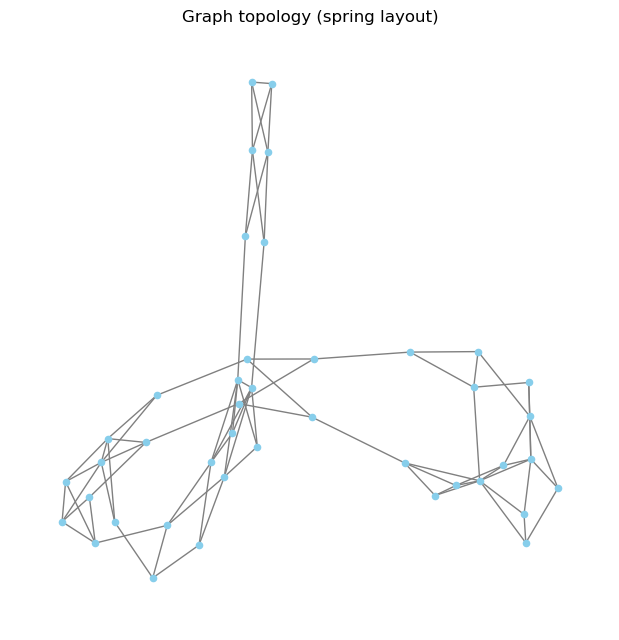

In [21]:
import matplotlib.pyplot as plt

pos = nx.spring_layout(G_nx, seed=42)
plt.figure(figsize=(6,6))
nx.draw(
    G_nx, pos,
    node_size=20,
    node_color='skyblue',
    edge_color='gray',
    with_labels=False
)
plt.title("Graph topology (spring layout)")
plt.show()

In [5]:
print("Number of graphs:", len(dataset))
print("Number of classes:", dataset.num_classes)

Number of graphs: 1113
Number of classes: 2


In [5]:
loader = DisjointLoader(dataset, batch_size=32, epochs=10)

In [7]:
loader.load()

<_FlatMapDataset element_spec=((TensorSpec(shape=(None, 4), dtype=tf.float64, name=None), SparseTensorSpec(TensorShape([None, None]), tf.float64), TensorSpec(shape=(None,), dtype=tf.int64, name=None)), TensorSpec(shape=(None, 2), dtype=tf.float64, name=None))>

In [8]:
data = dataset[0]
print(data)

Data(edge_index=[2, 162], x=[42, 3], y=[1])


In [9]:
# 3. Print tensor shapes
print("Node features x shape:", data.x.shape)           # (num_nodes, num_node_features)
print("Edge index shape:", data.edge_index.shape)        # (2, num_edges)
print("Edge attributes shape:", 
      data.edge_attr.shape if data.edge_attr is not None else "None")

Node features x shape: torch.Size([42, 3])
Edge index shape: torch.Size([2, 162])
Edge attributes shape: None


In [10]:
G = to_networkx(data, to_undirected=True)
pos = nx.spring_layout(G, seed=42)

NameError: name 'to_networkx' is not defined